# Channel model domain setup

You may need to install `MITgcmutils` first:

`pip install MITgcmutils` (https://mitgcm.readthedocs.io/en/latest/utilities/utilities.html)`

In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import os
import numpy as np
import matplotlib.pylab as plt
import pickle
import importlib
import shutil


from scipy.interpolate import make_interp_spline

import sys
sys.path.insert(0,'../main_scripts')

# import build_domain_funcs as build_domain
import build_domain_funcs_noise_ramp2ridge as build_domain
import run_config_funcs as rcf # import helpter functions
import mitgcm_physics_params as mpp
import gsw
#NBC edits
# !pip install opensimplex
import opensimplex
# NBC edits done

## Gather work environment info

In [ ]:
!pwd

In [ ]:
print(os.environ['OAK'])
print(os.environ['SCRATCH'])
print(os.environ['HOME'])
print(os.environ['GROUP_SCRATCH']) 
print(os.environ['GROUP_HOME'])

In [ ]:
group_scratch_dir = '/scratch/groups/earlew' #os.environ['GROUP_SCRATCH'] 
group_home_dir = '/home/groups/earlew' #os.environ['GROUP_HOME'] # recommended location to store  code 

# oak_dir = os.environ['OAK'] # we don't use OAK here, but this file system is for long term storage
# home_dir = os.environ['HOME'] # another option for storing personal code
pwd = os.getcwd()

In [ ]:
SUNet_ID = os.environ['HOME'].split('/')[-1]
print("SUNet_ID: %s" %SUNet_ID)
email = '%s@stanford.edu' %SUNet_ID

## Main run configuration

In [79]:
#----set high level run configurations----#

run_config = {}


run_config['run_name'] = 'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_2Lx'#'shelf_drake500_ramp2ridge500_nocontinent_noise100_H3km_v02_noaabw'#'shelf_H3km_v02_noaabw' #'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw'

#-------run time and time stepping-----------#
run_config['nyrs'] = 200 # simulaton time (years)
run_config['test'] = False # if True, run_config['nyrs'] will be shortened to a few time steps
run_config['nsteps_test'] = 500 

#-----domain config and parallelization----#
run_config['ncpus_xy'] = [50, 10] #[25, 10] # cpu distribution in the x and y directions
run_config['horiz_res_km'] = 10 # horizontal grid spacing (km)
# run_config['Lx_km'] = 3000 # domain size in x (km)
# run_config['Ly_km'] = 1500 # domain size in y (km)

# NBC edits
run_config['Lx_km'] = 2*4000 #3000 # domain size in x (km)
run_config['Ly_km'] = 2500 #1500 # domain size in y (km)

run_config['Lz'] = 3000 # SMOOTH domain size in z (m)
run_config['Ly_sponge_km'] = 100 # width of northern sponge layer
run_config['nz'] = 80# formerly 50 # number of depth grid points

# NOTE1: 
# While there is no official limit on the number of CPUs to request for a single job,
# it is good etiquette to use less than 500 cpus at any given time. If you feel like you need
# substantially more CPUs, please let the SERC/Sherlock admins know that you will be pushing through 
# an unusually large job.

#NOTE2:
# When setting up a new configuration, it's good practice to benchmark run performance wrt to the 
# number of cpus.

#NOTE3:
#the number of grid points in x and y should be multiples of the number of cpus.

#---model physics---#
run_config['evolve_salt'] = False
run_config['use_GMRedi'] = False # should be set to false for eddy permitting resolutions
run_config['periodic_forcing'] = False # note: the code is not yet set up to handle time-dependent forcing

#----checkpoint freq----#
# note: the model uses these files to restart runs
pChkptFreq = 5 #yrs #permanent checkpoint freq 
rolling_ChkptFreq = 1 #yrs rolling checkpoint freq (gets overwritten)

#---diagnostic output variables---#
# notes: 
#diag_fields_avg: list of time-averaged output variables. time window set by run_config['tavg_freq']
#diag_fields_inst: list of instantaneous output variables. time freq set by run_config['inst_freq

diag_fields_avg = ['UVEL', 'VVEL', 'THETA',  'VVELTH', 'UVELTH', 
                    'ETAN', 'UVELSQ', 'VVELSQ', 'WVEL']

diag_fields_inst = ['UVEL', 'VVEL', 'THETA', 'ETAN']

if run_config['test']:
    run_config['inst_freq'] = 10 # frequency of variable snapshot (multiples of timestep)
    run_config['tavg_freq'] = 50 # time window for averaging (multiples of timestep)
    
else:
    run_config['inst_freq'] = 6/12 # multiples of year
    run_config['tavg_freq'] = 1 # multiples of year
    
    
#---SLURM/job submission controls---#

wall_mins_per_sim_yr = (4/3)*60 # number of wall clock minutes it takes to generate 1 year of output

constrain_node_HW = True # if true, slurm requests a specific node hardware

mem_per_cpu_MB = 250 # memory to allocate per cpu/core

# NOTE 1: 
# the code uses wall_mins_per_sim_yr to estimate how much time to request on Sherlock.
# wall_mins_per_sim_yr depends on several factors, including domain size, # of grid points, time step, 
# number of evolved variables (temp, salinity, sea ice, etc), and the number of cpus. Therefore, the
# run efficiency needs to reevaluated with each new model configuration. To get an initial estimate,
# run the model run_config['test'] = True and then run the compute_run_efficiency.ipynb.

# NOTE 2:
# constrain_node_HW=True, helps ensure consistent run performance but may lead to increased wait time

# NOTE 3:
# like wall_mins_per_sim_yr, the necessary mem_per_cpu_MB will vary based with each model config
# the summary email after each run will provide stats on memory usage.

In [80]:
# less important run config parameters

MITgcm_release = 'MITgcm-checkpoint67g' #mid-2019 release (have not tested other versions)
MITgcm_code_dir = os.path.join(group_home_dir, 'shared/mitgcm_releases', MITgcm_release)

# you probably don't need to touch this
run_config['use_MPI'] = True # for multi-processing
run_config['lf'] = '\r\n' # linebreak characters 
run_config['exps_dir'] = os.path.join(group_scratch_dir, '%s/research/modeling/MITgcm/experiments' %SUNet_ID) 
run_config['run_dir'] = os.path.join(run_config['exps_dir'], run_config['run_name'])

In [81]:
run_config

{'run_name': 'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_2Lx',
 'nyrs': 200,
 'test': False,
 'nsteps_test': 500,
 'ncpus_xy': [50, 10],
 'horiz_res_km': 10,
 'Lx_km': 8000,
 'Ly_km': 2500,
 'Lz': 3000,
 'Ly_sponge_km': 100,
 'nz': 80,
 'evolve_salt': False,
 'use_GMRedi': False,
 'periodic_forcing': False,
 'inst_freq': 0.5,
 'tavg_freq': 1,
 'use_MPI': True,
 'lf': '\r\n',
 'exps_dir': '/scratch/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments',
 'run_dir': '/scratch/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments/shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_2Lx'}

## Generate new experiment directory and copy over defaults

In [82]:
# create experimentary directory on SCRATCH and copy over default configuration
# NOTE: this step does not overwrite existing directories. 
run_subdir_list = ['build', 'code', 'input', 'results']
for subdir in run_subdir_list:
    run_config['%s_dir'% subdir] = os.path.join(run_config['run_dir'], subdir)
    os.makedirs(run_config['%s_dir'% subdir], exist_ok=True)
     
# copy over defaults
default_dirs = os.listdir('DEFAULTS/')
for dir00 in default_dirs:
    
    if dir00.startswith('.'):
        continue
        
    default_dir = 'DEFAULTS/%s/'%dir00
    default_files = os.listdir(default_dir)
    dst_dir = os.path.join(run_config['run_dir'], dir00)
    
    for file in default_files:

        if file.startswith('.'):
            continue
        else:
            src_fpath = os.path.join(default_dir, file)
            shutil.copy2(src_fpath, dst_dir)

In [83]:
# just to see what the default files
#os.listdir('DEFAULTS/code')

In [84]:
print(run_config['run_dir'])
print(os.listdir(run_config['run_dir']))

/scratch/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments/shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_2Lx
['results', 'code', 'build', 'input']


In [85]:
# create new analysis sub-dir in your home directory
analysis_dir = '../analysis/%s'%run_config['run_name']
os.makedirs(analysis_dir, exist_ok=True)

# copy analyis notebook (if none already exist)
analysis_file_exists = False
files = os.listdir(analysis_dir)
for f in files:
    if f.endswith('.ipynb'):
        analysis_file_exists = True
        print("analysis file exists. Will not overwrite.")
        break
        
if analysis_file_exists==False:
    src = '../analysis/quick_analysis_demo.ipynb'
    shutil.copyfile(src, os.path.join(analysis_dir, 'quick_analysis.ipynb'))

## Domain  and grid parameters

In [86]:
secsInDay = 24*60*60
secsInYear = 365*secsInDay
mInkm = 1000

# set domain size
domain_params = {}
domain_params['Lx'] = run_config['Lx_km']*mInkm # domain size in x (m)
domain_params['Ly'] = run_config['Ly_km']*mInkm # domain size in y (m)
domain_params['L_sponge'] = run_config['Ly_sponge_km']*mInkm # width of northern sponge layer (m) # move to main control?
domain_params['H'] = run_config['Lz'] # max domain depth (m)
# NBC note: changed H to domain depth for noisy seafloor

In [87]:
#---grid parameters ---# 

# NOTE: the only thing you may need to change here is the number of z-grid points)
grid_params = {}

grid_params['nSx'] = 1 # num of tiles per processor in x-direction
grid_params['nSy'] = 1 # num of tiles per processor in y-direction
grid_params['nTx'] = 1 # num of threads per processor in x-direction
grid_params['nTy'] = 1 # num of threads per processor in y-direction
grid_params['OLx'] = 3 # num of overlapping x-gridpoints per tile
grid_params['OLy'] = 3 # num of overlapping y-gridpoints per tile
grid_params['Nr'] = run_config['nz'] # num of z-grid points

grid_params['nPx'] = run_config['ncpus_xy'][0] #num of processors in x-direction
grid_params['nPy'] = run_config['ncpus_xy'][1] #num of processors in x-direction

grid_params['Nx'] = domain_params['Lx']/(run_config['horiz_res_km']*mInkm)
grid_params['Ny'] = domain_params['Ly']/(run_config['horiz_res_km']*mInkm)

print("Nx: %s" %grid_params['Nx'])
print("Ny: %s" %grid_params['Ny'])

grid_params['sNx'] = grid_params['Nx']/grid_params['nPx']#num of x-gridpoints per tile
grid_params['sNy'] = grid_params['Ny']/grid_params['nPy'] #num of y-gridpoints per tile

# NOTE: sNx and sNy should be whole numbers/integers. As long we keep the horizontal resolution,
# domain dimesions, and number of cpus to be multiples of five, we should be ok. 

for key, param  in grid_params.items():
    assert param%1==0, "grid parameter needs to be an integer"
    grid_params[key] = int(param)
    
print(grid_params)
#run_config['grid_params'] = grid_params

# grid_params cont'd
grid_params['usingCartesianGrid'] = True
grid_params['usingSphericalPolarGrid'] = False 

# horizontal grid spacing
grid_params['delX'] = (domain_params['Lx']/grid_params['Nx'])*np.ones(grid_params['Nx'])
grid_params['delY'] = (domain_params['Ly']/grid_params['Ny'])*np.ones(grid_params['Ny'])


Nx: 800.0
Ny: 250.0
{'nSx': 1, 'nSy': 1, 'nTx': 1, 'nTy': 1, 'OLx': 3, 'OLy': 3, 'Nr': 80, 'nPx': 50, 'nPy': 10, 'Nx': 800, 'Ny': 250, 'sNx': 16, 'sNy': 25}


Text(0.5, 0, 'Vertical grid point')

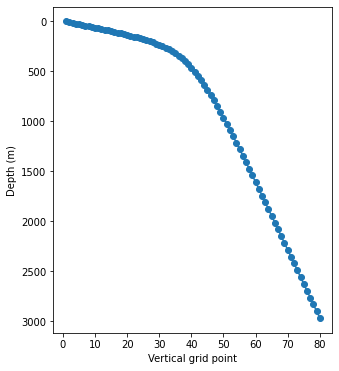

In [88]:
#---vertical grid spacing---#

# grid spacing increases with depth using tanh function
zidx = np.arange(1, grid_params['Nr']+1)
aa = 10
dz1 = 2*domain_params['H']/grid_params['Nr']/(aa+1) # Niall update this to be true H_min if noise
dz2 = aa*dz1
dz = dz1 + ((dz2-dz1)/2)*(1+np.tanh((zidx-((grid_params['Nr']+1)/2))/aa)) # this functional form can be updated
zz1 = np.append([0], np.cumsum(dz))
zz = -(zz1[:-1] + np.diff(zz1)/2) # layer midpoints

grid_params['delR'] = dz
grid_params['hFacMinDr'] = dz.min()

plt.figure(figsize=(5, 6))
plt.plot(zidx, np.abs(zz), '-o')
plt.gca().invert_yaxis()
plt.ylabel("Depth (m)")
plt.xlabel("Vertical grid point")
#plt.yscale("log")

In [89]:
# import numpy as np
# import matplotlib.pyplot as plt
from scipy.optimize import root_scalar
# import os

def stretched_grid_with_total_length(n, dz_min, H):
    """
    Generate a non-uniform grid on [0, H] with n points,
    using geometric spacing that starts with dz_min.

    Parameters:
        n (int): Number of grid points
        dz_min (float): Minimum grid spacing at z=0
        H (float): Total domain length

    Returns:
        z (ndarray): Grid coordinates of length n
    """

    def length_eq(r):
        """Equation for total length based on geometric series sum."""
        if r == 1.0:
            return dz_min * (n - 1) - H
        return dz_min * (1 - r**(n - 1)) / (1 - r) - H

    # Solve for r numerically
    sol = root_scalar(length_eq, bracket=[1.00001, 100.0], method='bisect')

    if not sol.converged:
        raise RuntimeError("Failed to find stretching factor r")

    r = sol.root

    # Build the grid
    dz = dz_min * r**np.arange(n - 1)
    z = np.zeros(n)
    z[1:] = np.cumsum(dz)
    return z

In [90]:
# dz_min = 20
# nz = run_config['nz']#100
# # grid_params['Nr']=nz
# # Lz = 3000
# zidx = np.arange(nz)

# # zz = stretched_grid_with_total_length(nz, dz_min, Lz)
# zz = stretched_grid_with_total_length(grid_params['Nr']+1, dz_min=15, H=run_config['Lz'])

# print("min dz: %.1f" %np.diff(zz).min())
# print("max dz: %.1f" %np.diff(zz).max())

# dz = np.diff(zz)
# zz1 = np.append([0], np.cumsum(dz))
# zz = -(zz1[:-1] + np.diff(zz1)/2)

# print("min dz: %.1f" %np.diff(zz).min())
# print("max dz: %.1f" %np.diff(zz).max())
# # print(np.diff(zz).max())

# fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# plt.sca(axes[0])
# plt.plot(zidx, -zz, '-o')
# #plt.gca().invert_yaxis()
# plt.ylabel("z (m)")
# plt.xlabel("Vertical grid point")
# plt.gca().invert_yaxis()


# plt.sca(axes[1])
# plt.plot(zidx[:-1], np.diff(zz), '-o')
# plt.ylabel("dz (m)")
# plt.xlabel("Vertical grid point")

## Physical parameters

In [92]:
params01 = mpp.get_params01(run_config, grid_params)

# add or update params01 below
# params01['sBeta'] = 0.0 #<--update if evolving salinty

Adding southern shelf...


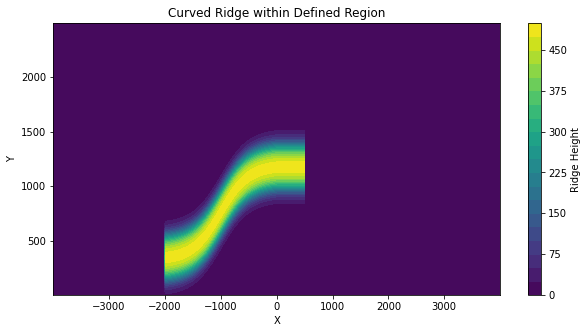

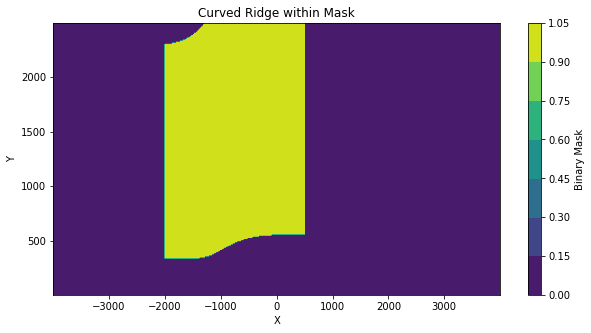

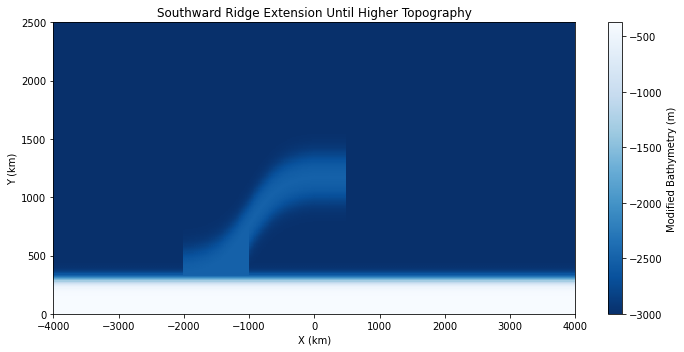

Adding topographic noise...
L=(240000.0,)
L=(120000.0,)
L=(60000.0,)
L=(30000.0,)
L=(9000.0,)
shape of delambs: (250, 800)
Check: Mean of (supposedly demeaned) lambda:2.8194335754960775e-16
Check: Max abs of final lambda:100.0
Check: Root mean square:32.86078107516929
shape of delambs: (250, 800)
shape of h: (800, 250)


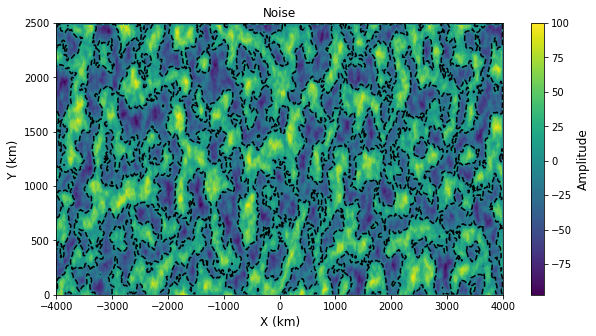

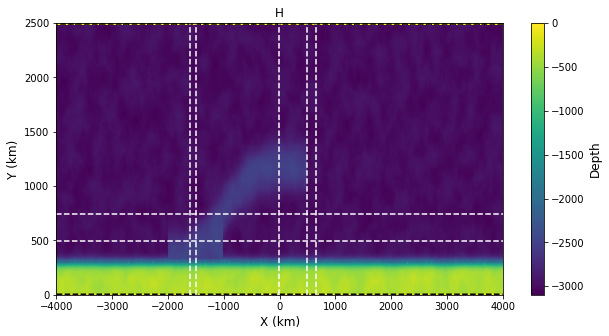

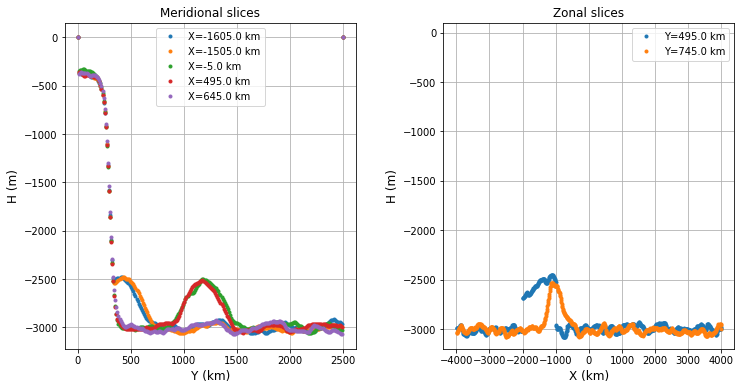

In [93]:
# NOTES: This step uses some custom functions from build_domain. 
# You can use this to add elongated ridges and continent, with cutouts for passages. 
# You'll need to write your code to add more complex features

importlib.reload(build_domain)

# plotting
dx = domain_params['Lx']/grid_params['Nx'] # x-grid res
xx = np.arange(grid_params['Nx'] )*dx
xx = xx-np.mean(xx) # offset so that x=0 is in the center of the domain

    # meridional grid   
dy = domain_params['Ly']/grid_params['Ny']   # y-grid res
yy = np.cumsum(dy*np.ones(grid_params['Ny'] )) - dy/2 
    # Y increases with increasing latitude. Also, following Andrew and offseting Y by dy/2)

    # Plotting mesh
YY, XX = np.meshgrid(yy, xx)

# Topographic parameters (find better names)
domain_params['add_SS'] = True # add southern shelf
domain_params['add_DP'] = False # add drake passage
domain_params['add_ZR'] = False # add zonal ridge
domain_params['add_MR'] = False # add meridional ridge
domain_params['add_SAC'] = False # add scotia arc channels
# NBC edits
domain_params['add_NOISE'] = True # add bathymetric noise everywhere
domain_params['add_CR'] = False # add curved ridge
domain_params['add_R2R'] = True # add ramp to ridge
domain_params['add_SAP'] = False # add small abyssal plain
domain_params['add_RP'] = False # add a Ross plain, and a taper. Only defined with Ramp to Ridge.
# NBC edits done


# NBC edits
# domain_params['SS_H'] = 2500 # shelf height (m)
domain_params['SS_H'] = int((3500/4000)*domain_params['H']) # NBC edits - rescaled continental shelf height 
# NBC edits done

domain_params['SS_slope_hW'] = 50*mInkm; # Half-width of shelf slope (m)
domain_params['SS_slope_Y'] = 300*mInkm # Meridional position of shelf slope (m)

# NBC edits
domain_params['NOISE_Li'] = 1E3*np.array([240, 120, 60, 30, 9]) # trying to mimic Styles

### 11/7/24 NBC edit: Make the maximum height of the noise 150 meters, not 300 meters. The ratio we are interested in is Max Noise / Sill Height. Used to be 300/375, now will be 150/375 < 1/2.
domain_params['NOISE_maxlam'] = 100#300/2 # meters, maximum magnitude of noise peak
# domain_params['NOISE_amp'] = np.array([8, 4, 2, 1, 0.3]) # trying to mimic Styles

# NOTE: to create a drake passage (DP), the code adds a meridional continent then carves out an opening
domain_params['slope_hW'] = domain_params['SS_slope_hW']; # Half-width of shelf slope beyond southern shelf (m)



# NBC Edits - rescaling vertical features based on EW2022 paper
domain_params['DP_continent'] = False # added 2/23/2025, goal of cutting out continent of ridge
if ~domain_params['DP_continent']:
    domain_params['MR_H_given_DPnoC'] = 500#750*1
# domain_params['DP_sill_H'] = 1500 # Height of drake passage ridge (m)
# domain_params['DP_sill_H'] = int((500/4000)*domain_params['H']) # Height of drake passage ridge (m)
domain_params['DP_sill_H'] = 500#750*1 # NBC edits 3/18/2025 only changed from curved ridge # Height of drake passage ridge (m)
# NBC Edits done

# NBC edits
# domain_params['DP_Y_mid'] = 800*mInkm # Center latitude of Drake Passage
domain_params['DP_Y_mid'] = 1500*mInkm # (Previous) Center latitude of Drake Passage # commented 14 March 2025 testing curved ridge
# NBC edits done

# domain_params['DP_X'] = -1500*mInkm # Longitudinal position of Drake Passage
domain_params['DP_X'] = -1000*mInkm # Longitudinal position of Drake Passage
domain_params['DP_dX'] = 250*mInkm # Longitudinal width of slope of Drake passage ridge (m)

# NBC edits
# domain_params['DP_dY'] = 200*mInkm # Latitudinal extent of drake passage ridge (m)
domain_params['DP_dY'] = 500*mInkm # Latitudinal extent of drake passage ridge (m) # commented 14 March 2025 testing curved ridge

# break for more thoughtful coding

val = domain_params['SS_H']*(1-np.tanh((YY-domain_params['SS_slope_Y'])/
                                             domain_params['SS_slope_hW']))/2 # shelf slope
# yshelf = smallest y value where val[0,:] < 1
# Find the indices where val[0, :] is less than 1
indices = np.where(val[0, :] < 1500)[0]
# Get the smallest y value corresponding to those indices
if indices.size > 0:
    yshelf = YY[0, indices[0]]  # Take the first y value where condition is met
else:
    yshelf = None  # No valid values found
domain_params['DP_Y_mid1'] = (domain_params['DP_Y_mid']+domain_params['DP_dY']/2+yshelf/1)/2#(1500-750)*mInkm # (Previous) Center latitude of Drake Passage
domain_params['DP_dY1'] = (domain_params['DP_Y_mid']+domain_params['DP_dY']/2-yshelf/1)#(500+750+375)*mInkm # Latitudinal extent of drake passage ridge (m)
# NBC edits done

domain_params['MR_HoS'] = 100 # height above sea level of meridional ridge (m)



# zonal ridge dimensions
# domain_params['ZR_H'] = 2000 # Height of zonal ridge (m)
domain_params['ZR_H'] = 500#750*1 # Height of zonal ridge (m) - edit for Ross
# NBC edits - circumpolar ridge
# domain_params['ZR_dX'] = 4000*mInkm # zonal length of ZR (m)
# NBC edits done
# domain_params['ZR_dX'] = 2000*mInkm # zonal length of ZR (m)
domain_params['ZR_dX'] = 2625*mInkm # zonal length of ZR (m)


domain_params['ZR_dY'] = 150*mInkm # Meridional extent of drake passage ridge (m)
domain_params['ZR_Y_mid'] = (domain_params['DP_Y_mid']
                             - domain_params['DP_dY']/2 
                             - domain_params['ZR_dY']/2)# Center latitude of zonal ridge

# NBC edits
# domain_params['ZR_X_min'] = domain_params['DP_X']+150*mInkm# Longitudinal start of ZR
# domain_params['ZR_X_min'] = domain_params['DP_X']+125*mInkm# Longitudinal start of ZR
domain_params['ZR_X_min'] = -2000*mInkm# Longitudinal start of ZR

domain_params['ZR_intersect'] = True # would intersect passage - zonal ridge topography wins



# meridional ridge dimensions
# for a seamount

# domain_params['MR_H'] = 1000 # Height of zonal ridge (m)

# domain_params['MR_dX'] = 300*mInkm # zonal length of MR (m)

# domain_params['MR_dY'] = 400*mInkm # Meridional extent (m)
# domain_params['MR_Y_mid'] = 500*mInkm # Center latitude of meridional ridge

# domain_params['MR_X_min'] = domain_params['ZR_X_min'] + domain_params['ZR_dX'] - domain_params['MR_dX']/2# Longitudinal start of MR

# for cleaning up submerged meridional ridge & drake passage
domain_params['MR_H'] = -1500 # Height of zonal ridge (m)

domain_params['MR_dX'] = 300*mInkm # zonal length of MR (m)

domain_params['MR_dY'] = 150*mInkm # Meridional extent (m)
domain_params['MR_Y_mid'] = 150*mInkm # Center latitude

domain_params['MR_X_min'] = domain_params['DP_X']-150*mInkm # Longitudinal start

# add curved ridge
# x1 is set by domain_params['DP_X']
domain_params['H_CR'] = 500#750*1 # 1500 was previous
domain_params['X2'] = 0 # setting the right end of the curved ridge
indices2 = np.where(val[0, :] < 1)[0]

# Get the smallest y value corresponding to those indices
if indices2.size > 0:
    yshelf2 = YY[0, indices2[0]]
domain_params['Y1'] = yshelf2
# y2 is set by domain_params['ZR_Y_mid']

# add ramp to ridge
indices3 = np.where(val[0, :] < domain_params['H_CR'])[0]
# Get the smallest y value corresponding to those indices
if indices3.size > 0:
    yshelf3 = YY[0, indices3[0]]
domain_params['Y1R2R'] = yshelf3
if domain_params['add_R2R']:
    domain_params['R2R_piecewiselinear'] = False
    domain_params['R2R_shear'] = False    
    domain_params['R2R_shear_cut'] = False 


# add scotia arc channels
domain_params['SAC_X0'] = [-1000*mInkm] 
domain_params['SAC_dX'] = 200*mInkm 
domain_params['SAC_sill_H'] = 1000

# add a small abyssal plain
domain_params['SAP_cos_H'] = 100
domain_params['SAP_step_flag'] = False
domain_params['SAP_step_H'] = 100

# add a Ross plain and taper
domain_params['RP_step_H'] = 250*1




# bathy_h = build_domain.add_bathy(run_config, domain_params, grid_params, cmap='viridis',
#                                  show_plot=True, x_slices_km=[-1000, 0], y_slices_km=[1000])

# NBC edits - plot a different meridional slice
bathy_h = build_domain.add_bathy(run_config, domain_params, grid_params, cmap='viridis',
                                 show_plot=True, x_slices_km=[-1600, -1500, 0, 500, 650], y_slices_km=[500, 750])#, 837.5, 1000, 1175])
# NBC edits done

# save bathymetry file to input directory
input_fnames = {}
input_fnames['bathyFile'] = 'bathyFile.bin'

bathy_fpath = os.path.join(run_config['input_dir'], input_fnames['bathyFile'])
with open(bathy_fpath, 'wb') as f:
    bathy_h.T.astype('>f8').tofile(f) #<--- need to transpose (mitgcm expects (z,) y, x)
    
    

    
# plt.figure(figsize=(10, 5))
# pp = plt.pcolormesh(XX/1e3, YY/1e3, bathy_h, vmin=bathy_h.min(), vmax=0, cmap='viridis')
# plt.contour(XX/1e3, YY/1e3, bathy_h, [-5], colors='k')
# ax0 = plt.gca()
# plt.ylabel('Y (km)', fontsize=12)
# plt.xlabel('X (km)', fontsize=12)
# plt.title('H')
        
# cb= plt.colorbar(pp)
# cb.set_label('Depth', fontsize=12)

# # plt.xlim(-1650, -1350)
# # plt.ylim(200, 400)
# plt.xlim(-1650, -1300)
# plt.ylim(1050, 1250)

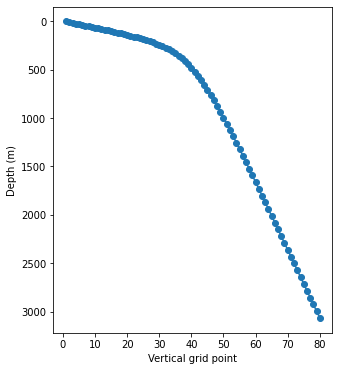

In [101]:
if domain_params['add_NOISE'] or domain_params['add_SAP']: # resetting your vertical coordinate to accomodate bumpy base
    #---vertical grid spacing---#
    if domain_params['add_NOISE']:
        H_min = domain_params['H']+domain_params['NOISE_maxlam'] # will be positive
    else:
        H_min = np.abs(bathy_h.min())

    dz1 = 2*H_min/grid_params['Nr']/(aa+1) # Niall update this to be true H_min if noise
    dz2 = aa*dz1
    dz = dz1 + ((dz2-dz1)/2)*(1+np.tanh((zidx-((grid_params['Nr']+1)/2))/aa)) # this functional form can be updated
    zz1 = np.append([0], np.cumsum(dz))
    zz = -(zz1[:-1] + np.diff(zz1)/2) # layer midpoints

    grid_params['delR'] = dz
    grid_params['hFacMinDr'] = dz.min()

    plt.figure(figsize=(5, 6))
    plt.plot(zidx, np.abs(zz), '-o')
    plt.gca().invert_yaxis()
    plt.ylabel("Depth (m)")
    plt.xlabel("Vertical grid point")
    #plt.yscale("log")

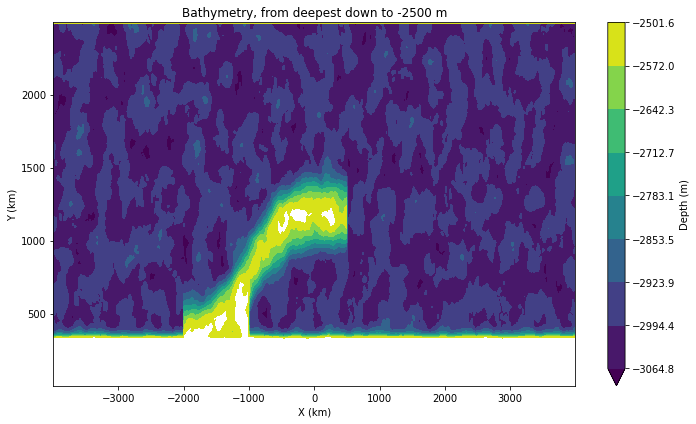

In [105]:
import numpy as np
import matplotlib.pyplot as plt

# ── 1) Subset zz so that we only keep depths ≤ -2000 m ────────────────────────
max_ceiling = -2500.0   # “2 km below surface” as a negative value
# For example, if zz = [-5, -15, -30, …, -4000], we only want those ≤ -2000.
levels = zz[zz <= max_ceiling]
if levels.size == 0:
    raise ValueError("No zz‐levels are deeper than or equal to -2000 m!")

# Note: If you want to force an exact −2000 m boundary even if zz doesn’t contain it:
# levels = np.sort(np.concatenate([zz[zz < max_ceiling], [-2000.0]]))
# but in most workflows, simply taking zz[zz <= -2000] is enough.

# ── 2) Draw a contourf that only uses these “deep‐water” levels ─────────────────
plt.figure(figsize=(10, 6))

cs = plt.contourf(
    XX/1e3,                # convert X → km
    YY/1e3,                # convert Y → km
    bathy_h,               # your 2D bathymetry array (negative values)
    levels=np.flip(levels),         # only draw bands at (e.g.) −2000, −2150, … down to the deepest
    cmap="viridis",
    extend="min"           # 'min' will add a downward arrow if some depths < levels.min()
                           # (i.e. deeper than your deepest level). 
                           # If you know there is nothing deeper than levels.min(), you can use 'neither'.
)

# ── 3) Create a truly discrete colorbar ────────────────────────────────────────
cbar = plt.colorbar(
    cs,
    spacing="uniform",     # force one box per level‐interval
    ticks=levels           # tick at each depth in “levels”
)
cbar.set_label("Depth (m)")

# ── 4) Finish plotting labels/axes ────────────────────────────────────────────
plt.xlabel("X (km)")
plt.ylabel("Y (km)")
plt.title(f"Bathymetry, from deepest down to {max_ceiling:.0f} m")
# plt.gca().invert_yaxis()   # so larger (negative) depths appear lower if you prefer
plt.tight_layout()
plt.show()


## Ocean initialization and surface forcing

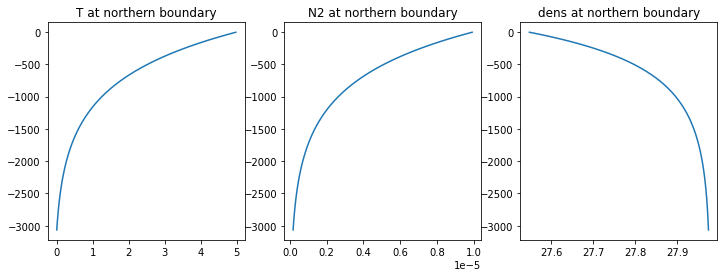

In [106]:
# specify T and S along northern boundary

# Exponential background temperature  
Hscale = 750
mintemp = 0
maxtemp = 5
# NBC: true H_Min if noise, else standard H
if domain_params['add_NOISE'] or domain_params['add_SAP']:
    domain_params['H'] = H_min
    run_config['Lz'] = H_min # trying to see if adding these works after we've made the bathymetry already.
    H = H_min    
else:
    H = domain_params['H']
temp_north = mintemp + (maxtemp-mintemp)*(np.exp(zz/Hscale)-np.exp(-H/Hscale))/(1-np.exp(-H/Hscale))

# Constant background salinity (currently unused)
sRef = 35;    
sNorth = sRef*np.ones(grid_params['Nr'])

plt.figure(figsize=(12, 4))
plt.subplot(131)
plt.plot(temp_north, zz)
plt.title("T at northern boundary")

# compute N2 across meridional transect
plt.subplot(132)
Tz = np.gradient(temp_north, zz, edge_order=2)
N2 = params01['tAlpha']*params01['gravity']*Tz
plt.title("N2 at northern boundary")

plt.plot(N2, zz)

# compute N2 across meridional transect
plt.subplot(133)
Tz = np.gradient(temp_north, zz, edge_order=2)
pdens = gsw.sigma0(sRef, temp_north)
plt.title("dens at northern boundary")
#plt.xlim(27.6, 28.3)

plt.plot(pdens, zz)

### 3D initial hydrography

In [107]:
# initialize entire domain using northern BCs
# note: there is 
grid_size = (grid_params['Nx'], grid_params['Ny'], grid_params['Nr'])
temp_init = np.ones(grid_size)*temp_north

# add some random noise
# EW note: not sure why this necessary
temp_noise = 0.1*np.random.rand(*grid_size) 
temp_init += temp_noise-temp_noise.mean()


# save to input file
input_fnames['hydrogThetaFile'] = 'hydrogThetaFile.bin'

temp_fpath = os.path.join(run_config['input_dir'],  'hydrogThetaFile.bin')
with open(temp_fpath, 'wb') as f:
    temp_init.T.astype('>f8').tofile(f) #<--- need to transpose to get Fortran order

# NOTE: need to repeat these steps when evolving salinity

### implement sponge layer along northern boundary

In [108]:
# define horizontal grid
dx = domain_params['Lx']/grid_params['Nx'] # x-grid res
xx = np.arange(grid_params['Nx'] )*dx
xx = xx-np.mean(xx) # offset so that x=0 is in the center of the domain
  
dy = domain_params['Ly']/grid_params['Ny']   # y-grid res
yy = np.cumsum(dy*np.ones(grid_params['Ny'])) - dy/2 

XX, YY = np.meshgrid(xx, yy)

In [109]:
# define some paramters

useRBCtemp = True
useRBCsalt = False # modify if evolving salinity
useRBCuVel = False
useRBCvVel = False
tauRelaxT = 7.0*secsInDay # relaxation time scale
tauRelaxS = 1.0*secsInDay # modify if evolving salinity
tauRelaxU = 1.0*secsInDay
tauRelaxV = 1.0*secsInDay

rbcs_params01 = {}
rbcs_params01['useRBCtemp'] = useRBCtemp
rbcs_params01['useRBCsalt'] = useRBCsalt
rbcs_params01['useRBCuVel'] = useRBCuVel
rbcs_params01['useRBCvVel'] = useRBCvVel
rbcs_params01['tauRelaxT'] = tauRelaxT
rbcs_params01['tauRelaxS'] = tauRelaxS
rbcs_params01['tauRelaxU'] = tauRelaxU
rbcs_params01['tauRelaxV'] = tauRelaxV

rbcs_params02 = {}


# set relaxation temp
temp_relax = temp_north*np.ones(grid_size)

# set relaxation mask
northRelaxFac = 1
sponge_Y_min = domain_params['Ly'] - domain_params['L_sponge']
sponge_yi = yy>=sponge_Y_min

msk_vals = (1/northRelaxFac)*(yy[sponge_yi]-sponge_Y_min)/domain_params['L_sponge']
print(msk_vals)

msk = np.zeros(grid_size)
msk[:, sponge_yi, :] = msk_vals[np.newaxis, :, np.newaxis]

# save relaxation (i.e. sponge layer) files
input_fnames['relaxTFile'] = 'sponge_temp.bin'
input_fnames['relaxMaskFile(1)'] = 'rbcs_temp_mask.bin'

fpath = os.path.join(run_config['input_dir'], input_fnames['relaxTFile'])
with open(fpath, 'wb') as f:
    temp_relax.astype('>f8').T.tofile(f) #  
    
fpath = os.path.join(run_config['input_dir'], input_fnames['relaxMaskFile(1)'])
with open(fpath, 'wb') as f:
    np.asfortranarray(msk).astype('>f8').T.tofile(f) 
    
    
rbcs_params01['relaxTFile'] = input_fnames['relaxTFile']
rbcs_params01['relaxMaskFile(1)'] = input_fnames['relaxMaskFile(1)']

data_rbcs_params = [rbcs_params01, rbcs_params02]
rcf.write_data(run_config, data_rbcs_params, group_name='rbcs')

[0.05 0.15 0.25 0.35 0.45 0.55 0.65 0.75 0.85 0.95]


### Surface winds and heat fluxes

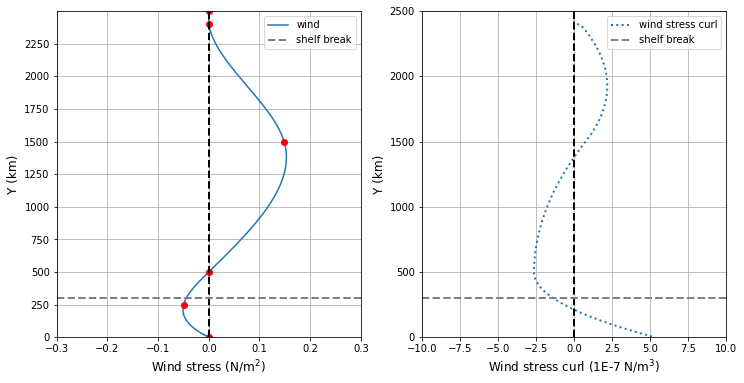

In [110]:
Ln = domain_params['L_sponge'] # length of northern sponge layer
Ys = domain_params['SS_slope_Y'] # location of shelf break 
Ly = np.round(domain_params['Ly'])

# # prescribe zonally uniform sinusoid winds 
# taux0 = 0.2
# taux = taux0*(np.sin(np.pi*yy/domain_params['Ly']))**2

# NBC edits - pasting Earle's wind profile from other scripts
tau_east_max=0.15 # decreased from 0.2
tau_west_max=0.05
Y_tau0=Ly*0.2 # latitude where tau=0

# zonal wind stress
taux_pts = {}
taux_pts['yy'] = np.array([0, Y_tau0/2, Y_tau0, Ly*0.6,  Ly-Ln, Ly])
taux_pts['values'] = np.array([-tau_west_max*0, -tau_west_max*0.99, 0, tau_east_max*0.99, 0, 0]) #NBC: Why 0.99 vs 1? What's the holdup?

spl = make_interp_spline(taux_pts['yy'], taux_pts['values'], k=3) 
taux = spl(yy)
taux[yy>(Ly-Ln)] = 0 # set forcing to zero over sponge layer



# plot wind profile
fz =12

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
plt.sca(axes[0])
plt.plot(taux, yy/1e3, label='wind')
plt.plot(taux_pts['values'], taux_pts['yy']/1e3, 'or') # NBC edits - turned this on.
plt.axvline(0, linestyle='--', linewidth=2, color='k')
plt.axhline(Ys/1e3, linestyle='--', linewidth=2, color='0.5', label='shelf break')
plt.xlim(-0.3, 0.3)
plt.yticks(np.arange(0, 2500, 250))
plt.xlabel("Wind stress (N/m$^2$)", fontsize=fz)
plt.ylabel("Y (km)", fontsize=fz)
plt.grid(True)
plt.ylim(0, Ly/1e3)
plt.legend(loc=0, fontsize=fz-2)


# compute and winds stress curl
dtaux_dy = np.gradient(taux, yy, edge_order=2) 

plt.sca(axes[1])
plt.plot(-dtaux_dy*1e7, yy/1e3, ':', linewidth=2, label='wind stress curl')
plt.xlabel("Wind stress curl (1E-7 N/m$^3$)", fontsize=fz)
plt.ylabel("Y (km)", fontsize=fz)
plt.xlim(-10, 10)
plt.ylim(0, Ly/1e3)
plt.grid(True)
plt.axvline(0, linestyle='--', linewidth=2, color='k')
plt.axhline(Ys/1e3, linestyle='--', linewidth=2, color='0.5', label='shelf break')
plt.legend(loc=0, fontsize=fz-2)
plt.subplots_adjust(hspace=0.3)
plt.show()

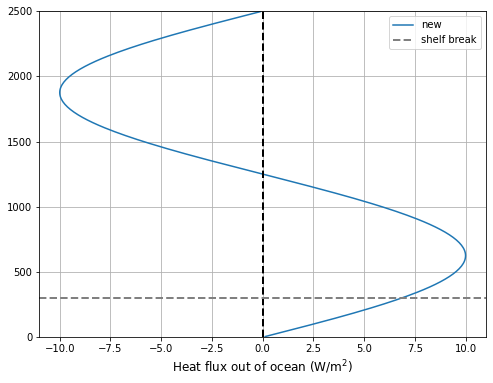

In [111]:
q0 = 10
# q0 = 10 * (1 - 0.25) # NBC edits: reduce heat flux out of the surface
q0_shel_anom = 50 
Ly_shelf = 150e3
q = q0*(np.sin(2*np.pi*yy/Ly)) # again use simple sinusoid
#q = q0_shel_anom*np.exp(-((yy+5e3)/Ly_shelf)**2)


#----------plot heat flux profile
plt.figure(figsize=(8, 6))
plt.plot(q, yy/1e3, label='new')
#plt.plot(qflux_pts['values'], qflux_pts['yy']/1e3, 'or')
plt.axvline(0, linestyle='--', linewidth=2, color='k')
plt.axhline(Ys/1e3, linestyle='--', linewidth=2, color='0.5', label='shelf break')
#plt.xlim(-10, 20)
plt.xlabel("Heat flux out of ocean (W/m$^2$)", fontsize=fz)
plt.grid(True)
plt.ylim(0, Ly/1e3)
plt.legend(loc=0, fontsize=fz-2)
ax1 = plt.gca()
plt.show()

/share/software/user/open/py-jupyterlab/2.3.2_py36/lib/python3.6/site-packages/ipykernel_launcher.py:17: MatplotlibDeprecationWarning: The 'extend' parameter to Colorbar has no effect because it is overridden by the mappable; it is deprecated since 3.3 and will be removed two minor releases later.


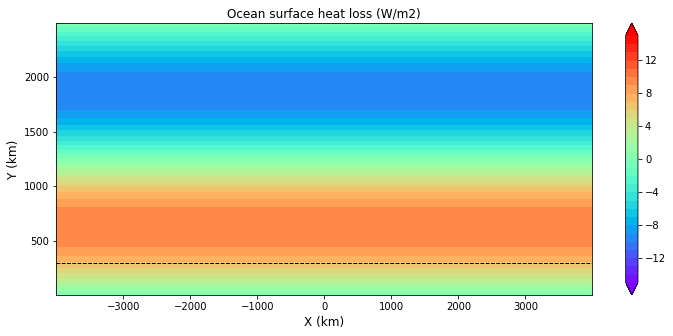

In [112]:
# expand to 2D
taux_2D = np.tile(taux[np.newaxis, :], (len(xx), 1))
qflux_2D = np.tile(q[np.newaxis, :], (len(xx), 1))


plt.figure(figsize=(12,5))
vmin, vmax = -q0*1.5, q0*1.5,
clvls = np.arange(vmin, vmax+0.1, 1)

plt.contourf(XX/1e3, YY/1e3, qflux_2D.T, clvls, vmin=vmin, vmax=vmax, cmap=plt.cm.rainbow, extend='both')
plt.axhline(Ys/1e3, linestyle='--', linewidth=1, color='k')
#plt.xticks(np.arange(-2000, 2001, 500))
ax1.tick_params(axis='both', which='major', labelsize=fz)
plt.ylabel("Y (km)", fontsize=fz)
plt.xlabel("X (km)", fontsize=fz)
plt.title("Ocean surface heat loss (W/m2)", fontsize=fz)
plt.colorbar(extend='both')


# NBC pastes Earle's code but not using it now - localized cooling

# #add localized region of intense buoyancy loss
# #add_local_Qaabw = True # TODO: move this control somewhere else
# Qaabw_max=150 # max cooling; W/m2
# aabw_xc = 500e3 # x location of 
# aabw_Lc = 200e3 # width of cooling region

# # if add_local_Qaabw:
# qflux_Ys = Qaabw_max #qflux_new_2D[yi.T].max()
# qflux_abbw = qflux_Ys*np.exp(-((XX.T-aabw_xc)/aabw_Lc)**2 - ((YY.T+5e3)/(Ys))**2)
# qflux_2D += qflux_abbw
# cs = plt.contour(XX/1e3, YY/1e3, qflux_abbw.T, np.arange(25, 201, 25), 
#                  colors='k', vmin=vmin, vmax=vmax, extend='both')

# plt.clabel(cs, cs.levels, inline=True, fontsize=fz-2)

# xidx = np.argmin(np.abs(aabw_xc-xx))
# qflux_aabw = qflux_2D[xidx, :] 

In [113]:
# NOTE: we could specify a time component to the surface forcing to create a 3D (x, y, t) file.

In [114]:
# save surface forcing
input_fnames['zonalWindFile'] = 'zonalWindFile.bin'
input_fnames['surfQfile'] = 'surfQFile.bin'

taux_fpath = os.path.join(run_config['input_dir'], input_fnames['zonalWindFile'])
with open(taux_fpath, 'wb') as f:
    taux_2D.T.astype('>f8').tofile(f)

qflux_fpath = os.path.join(run_config['input_dir'], input_fnames['surfQfile'])
with open(qflux_fpath, 'wb') as f:
    qflux_2D.T.astype('>f8').tofile(f)

## Vertical diffusivity 

In [116]:
diffKr = params01['diffKrT']*np.ones(grid_size)
kap_deep = 1e-3 # assume diffusivity is maximum at seafloor (m2/s)
H_kap = 300 # e-folding scale for diffusivity
#diffKr[ii, jj, :]
for ii in range(grid_params['Nx']):
    for jj in range(grid_params['Ny']):
        diffKrT_profile = np.exp(-(zz-bathy_h[ii,jj])/H_kap)
        diffKrT_profile[diffKrT_profile>1] = 1                                   
        diffKr[ii, jj, :] = params01['diffKrT'] + diffKrT_profile*kap_deep


Text(0, 0.5, 'Depth (m)')

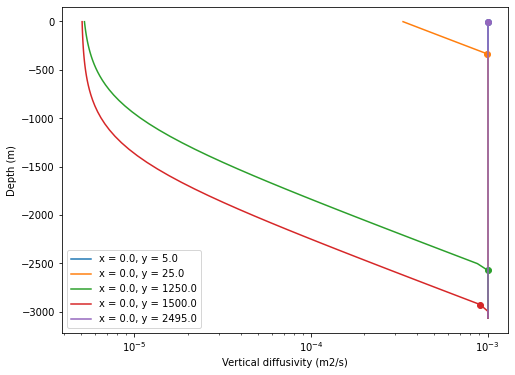

In [118]:
plt.figure(figsize=(8, 6))

xloc = xx.mean()
xidx = np.argmin(np.abs(xx-xloc))

# NBC edits - the plot looked different so investigating - got a much better sense for what is happening here.
# ylocs = [yy.mean(), 1500e3]
ylocs = [yy.min(), yy[2], yy.mean(), 1500e3, yy.max()]
# NBC edits done

for yloc in ylocs:
    
    yidx = np.argmin(np.abs(yy-yloc))
    
    p = plt.semilogx(diffKr[xidx, yidx, :], zz, label="x = %s, y = %s" %(xloc/1e3, yloc/1e3))
    
    zidx = np.argmin(np.abs(zz-bathy_h[xidx, yidx]))
    plt.semilogx(diffKr[xidx, yidx, zidx], zz[zidx], 'o', color= p[0].get_color())
    
plt.legend()
plt.xlabel('Vertical diffusivity (m2/s)')
plt.ylabel('Depth (m)')

In [119]:
# save diffusivity profile
input_fnames['diffKrFile'] = 'diffKrFile.bin'

diff_fpath = os.path.join(run_config['input_dir'], input_fnames['diffKrFile'])
with open(diff_fpath, 'wb') as f:
    diffKr.T.astype('>f8').tofile(f) # <--- need to transpose   

Text(0.5, 1.0, 'First baroclinic Rossby deformation radius (km)')

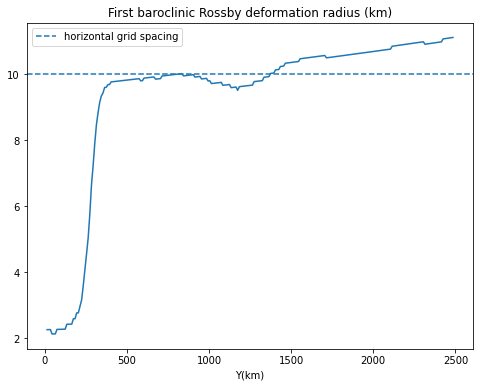

In [121]:
# compute internal wave speed
N = np.sqrt(N2)

x0 = 0
xidx = np.argmin(np.abs(xx-x0)) #

C_ig = np.zeros(len(yy))
for jj in range(len(yy)):
    for kk in range(len(zz)):
        if zz[kk]>bathy_h[xidx, jj]:
            C_ig[jj] = C_ig[jj] + N[kk]*dz[kk]
        else:
            continue
            
            
R_d = C_ig/(np.pi*np.abs(params01['f0']+params01['beta']*yy))
#print(R_d) 
# Note: R_d here not exactly the same as in matlab calculation but it is within a few percent.
# Tz is computed differently here

plt.figure(figsize=(8, 6))
plt.plot(yy[1:-1]/1e3, R_d[1:-1]/1e3)
plt.xlabel("Y(km)")
plt.axhline(run_config['horiz_res_km'], linestyle='--', label='horizontal grid spacing')
plt.legend()
plt.title("First baroclinic Rossby deformation radius (km)")

## Check numeric stability

In [122]:
# Upper bound for absolute horizontal fluid velocity (m/s)
Umax = 1.0 # Andrew's estimate

# Max gravity wave speed 
cmax = np.max(C_ig)

# Max gravity wave speed using total ocean depth
cgmax = Umax + cmax

# Advective CFL
deltaT_adv = np.min([0.5*dx/cmax,0.5*dy/cmax])

# Gravity wave CFL
deltaT_gw = np.min([0.5*dx/Umax,0.5*dy/Umax])

# CFL time step based on full gravity wave speed
deltaT_fgw = np.min([0.5*dx/cgmax,0.5*dy/cgmax])

deltaT_list = [deltaT_adv, deltaT_gw, deltaT_fgw]

#---Other stability conditions

# Inertial CFL time step (Sf0<=0.5)
deltaT_itl = 0.5/np.abs(params01['f0'])
deltaT_list.append(deltaT_itl)

# Time step constraint based on horizontal diffusion 
deltaT_Ah = 0.5*np.min([dx, dy])**2/(4*params01['viscAh'])  
deltaT_list.append(deltaT_Ah)

# Time step constraint based on vertical diffusion
deltaT_Ar = 0.5*np.min(dz)**2 / (4*params01['viscAr']) 
deltaT_list.append(deltaT_Ar)

# Time step constraint based on biharmonic viscosity 
deltaT_A4 = 0.5*np.min([dx,dy])**4/(32*params01['viscA4'])
deltaT_list.append(deltaT_A4)

# Time step constraint based on horizontal diffusion of temp 
deltaT_KhT = 0.4*np.min([dx,dy])**2/(4*params01['diffKhT'])
deltaT_list.append(deltaT_KhT)

# Time step constraint based on vertical diffusion of temp 
deltaT_KrT = 0.4*np.min(dz)**2 / (4*params01['diffKrT'] )
deltaT_list.append(deltaT_KrT)


deltaT = np.min(deltaT_list)
print("Minimum time step required: %.2f seconds" %deltaT)

deltaT = np.round(deltaT)

Minimum time step required: 978.61 seconds


/share/software/user/open/py-jupyterlab/2.3.2_py36/lib/python3.6/site-packages/ipykernel_launcher.py:36: RuntimeWarning: divide by zero encountered in double_scalars
/share/software/user/open/py-jupyterlab/2.3.2_py36/lib/python3.6/site-packages/ipykernel_launcher.py:40: RuntimeWarning: divide by zero encountered in double_scalars


## Numeric solvers and I/O controls

In [123]:
params02, params03, params04 = mpp.get_params02_04(run_config, grid_params, pChkptFreq)

In [124]:
# specify frequency of permanent checkpoint 
params03['pChkptFreq'] = pChkptFreq*secsInYear #
params03['chkptFreq'] = rolling_ChkptFreq*secsInYear

if run_config['test']:
    nTimeSteps = run_config['nsteps_test']
else:
    nTimeSteps = np.ceil(run_config['nyrs']*secsInYear/deltaT)


params03['endTime'] = int(params03['nIter0']*deltaT+nTimeSteps*deltaT)
params03['deltaT'] = np.round(deltaT)
grid_params['Nt'] = nTimeSteps
grid_params['deltaT'] = params03['deltaT']

In [125]:
# estimate completion time
sim_yrs = nTimeSteps*deltaT/secsInYear

comptime_hrs = sim_yrs*wall_mins_per_sim_yr/60
  
print("Estimate completion time: %.2f hrs" %comptime_hrs)
print("Estimate completion time: %.2f mins" %(comptime_hrs*60))

Estimate completion time: 266.67 hrs
Estimate completion time: 16000.00 mins


## Create 'data' files

In [126]:
# get data fnames param
params05 = {}
for key in input_fnames:
    if key.startswith('relax'):
        continue
    params05[key] = input_fnames[key]

In [127]:
data_params = [params01, params02, params03, params04, params05]
rcf.write_data(run_config, data_params, group_name='data', lf=run_config['lf'])

## Set inflow boundary conditions

In [128]:
obcs_params01, obcs_params02 = mpp.set_obcs_params(run_config, grid_params)

obcs_params = [obcs_params01, obcs_params02]
rcf.write_data(run_config, obcs_params, group_name='obcs')

In [129]:
# NOTE: This is mostly copied verbatim from Andrew's code.

## Set layers package

In [130]:
# NOTE: the layers package is useful for computing the overturning streamfunction

In [131]:
layers_params01 = {}

### Number of fields for which to calculate layer fluxes
layers_maxNum = 1

### Specify potential temperature
layers_name = 'TH'

### Potential temperature bounds for layers 
# note: one should check to see if these levels match the range of temperatures in the domain
# also, if salinity is being evolved, the layer bounds will need to be defined by density
layers_bounds = np.hstack([np.arange(-1, 1, 0.05), np.arange(1, 3, 0.2), np.arange(3, 7.2, 0.3),
                           np.arange(7.4, 9, 0.2), np.arange(9, 12.001, 0.1)])


# layers_bounds = np.hstack([np.arange(-1, 1, 0.05), np.arange(1, 3, 0.1), np.arange(3, 9, 0.25),
#                            np.arange(9, 12.001, 0.5)])
                           
### Reference level for calculation of potential density
layers_krho = 1    

### If set true, the GM bolus velocity is added to the calculation
if run_config['use_GMRedi']:
    layers_bolus = True
else:
    layers_bolus = False

### Layers
layers_params01['layers_bounds'] = layers_bounds
layers_params01['layers_krho'] = layers_krho
layers_params01['layers_name'] = layers_name
layers_params01['layers_bolus'] = layers_bolus

layers_params = [layers_params01]
rcf.write_data(run_config, layers_params, group_name='layers')

# create createLAYERSSIZEh
Nlayers = len(layers_params01['layers_bounds'])-1
rcf.createLAYERSSIZEh(run_config, Nlayers)

## Specify GM Redi

In [132]:
# NOTE: run_config['use_GMRedi']=False, the model will ignore all of this

gmredi_params01 = {}
gmredi_params01['GM_isopycK'] = 1000.0
gmredi_params01['GM_background_K'] = 1000.0
gmredi_params01['GM_maxSlope'] = 0.025
gmredi_params01['GM_taper_scheme'] = 'dm95'
gmredi_params01['GM_Scrit'] = 0.025
gmredi_params01['GM_Sd'] = 0.0025

gmredi_params = [gmredi_params01]
rcf.write_data(run_config, gmredi_params, group_name='gmredi')


# update GM ready package
if run_config['use_GMRedi']:
            
        
    new_data_pkg = ['# Packages\n', ' &PACKAGES\n', ' useDiagnostics=.TRUE.,\n',
                    ' useRBCS=.TRUE.,\n', ' useOBCS=.FALSE.,\n', ' useKPP=.TRUE.,\n',
                    ' useLayers=.TRUE.,\n', ' useBBL=.FALSE.,\n', ' useGMREDI=.TRUE.,\n',
                    ' /']

    new_package_config = ['gfd\n', 'diagnostics\n', 'timeave\n', 'rbcs\n',
                          'kpp\n', 'layers\n', 'gmredi']
    # back up old files
    input_fpath = os.path.join(run_config['run_dir'], 'code')
    src_fpath1 = os.path.join(input_fpath, 'data.pkg')
    shutil.copy2(src_fpath, src_fpath+'.old')
    
    src_fpath2 = os.path.join(code_fpath, 'packages.conf')
    shutil.copy2(src_fpath, src_fpath+'.old')
    
    # save new files
    with open(src_fpath1, 'w') as f:
        text = "".join(new_data_pkg)
        f.writelines(text)
        
    with open(src_fpath2, 'w') as f:
        text = "".join(new_package_config)
        f.writelines(text)   

## Specify Diagnostics

In [133]:

numdiags_avg = len(diag_fields_avg)
diag_phase_avg = 0.0

if run_config['test'] == True:
    diag_freq_inst = -run_config['inst_freq']*deltaT # negative values indicate snapshots at given interval
    diag_freq_avg = run_config['tavg_freq']*deltaT # positive values indicate time average over specified interval
else:
    diag_freq_inst = -run_config['inst_freq']*secsInYear 
    diag_freq_avg = run_config['tavg_freq']*secsInYear
    
    
diag_params01 = {}
diag_params01['diag_mnc'] = False #<---you would need to modify this if you want netcdf output

for ii in range(numdiags_avg):  
    n = ii+1
    diag_params01['fields(1,%s)'%n] = diag_fields_avg[ii]
    diag_params01['fileName(%s)'%n] = diag_fields_avg[ii]
    diag_params01['frequency(%s)'%n] = diag_freq_avg
    diag_params01['timePhase(%s)'%n] = diag_phase_avg

    
#--------specify instanteous fields (i.e. snapshots)--------#
#diag_fields_inst = ['UVEL', 'VVEL', 'THETA']
numdiags_inst = len(diag_fields_inst)
diag_phase_inst = 0.0

for ii in range(numdiags_inst):
    n = numdiags_avg+ii+1
    diag_params01['fields(1,%s)'%n] = diag_fields_inst[ii]
    diag_params01['fileName(%s)'%n] = diag_fields_inst[ii] + '_inst'
    diag_params01['frequency(%s)'%n] = diag_freq_inst
    diag_params01['timePhase(%s)'%n] = diag_phase_inst
    
print(diag_params01)
Ndiags = n

# write data.diagnostics files
diag_params02={}
diag_params = [diag_params01, diag_params02]
rcf.write_data(run_config, diag_params, group_name='diagnostics')

## create DIAGNOSTICS_SIZE.h
Nlevels = np.max([grid_params['Nr'], Nlayers])
rcf.createDIAGSIZEh(run_config, Ndiags, Nlevels)

{'diag_mnc': False, 'fields(1,1)': 'UVEL', 'fileName(1)': 'UVEL', 'frequency(1)': 31536000, 'timePhase(1)': 0.0, 'fields(1,2)': 'VVEL', 'fileName(2)': 'VVEL', 'frequency(2)': 31536000, 'timePhase(2)': 0.0, 'fields(1,3)': 'THETA', 'fileName(3)': 'THETA', 'frequency(3)': 31536000, 'timePhase(3)': 0.0, 'fields(1,4)': 'VVELTH', 'fileName(4)': 'VVELTH', 'frequency(4)': 31536000, 'timePhase(4)': 0.0, 'fields(1,5)': 'UVELTH', 'fileName(5)': 'UVELTH', 'frequency(5)': 31536000, 'timePhase(5)': 0.0, 'fields(1,6)': 'ETAN', 'fileName(6)': 'ETAN', 'frequency(6)': 31536000, 'timePhase(6)': 0.0, 'fields(1,7)': 'UVELSQ', 'fileName(7)': 'UVELSQ', 'frequency(7)': 31536000, 'timePhase(7)': 0.0, 'fields(1,8)': 'VVELSQ', 'fileName(8)': 'VVELSQ', 'frequency(8)': 31536000, 'timePhase(8)': 0.0, 'fields(1,9)': 'WVEL', 'fileName(9)': 'WVEL', 'frequency(9)': 31536000, 'timePhase(9)': 0.0, 'fields(1,10)': 'UVEL', 'fileName(10)': 'UVEL_inst', 'frequency(10)': -15768000.0, 'timePhase(10)': 0.0, 'fields(1,11)': 'VVE

## Generate eedata and SIZEh files

In [135]:
# create eedata
rcf.create_eedata(run_config, grid_params['nTx'], grid_params['nTy'])

# generate size.h file
rcf.createSIZEh(run_config, grid_params)

## Cluster configuraton

In [136]:
# Sherlock (Stanford)

cluster_params = {}
cluster_params['cluster_name'] = 'sherlock'
cluster_params['opt_file'] = 'darwin_amd64_gfortran_v2' #<-- may need to update this at some point
cluster_params['open_mpi_ver'] = '4.0.3' #'4.0.3' 4.1.2'
cluster_params['mpi_inc_dir'] = '/share/software/user/open/openmpi/%s/include' %cluster_params['open_mpi_ver'] 
cluster_params['netcdf_dir'] = '/share/software/user/open/netcdf/4.4.1.1'
cluster_params['use_mpi'] = True
cluster_params['use_pbs'] = True

cluster_params['username'] = SUNet_ID
cluster_params['email'] = email
cluster_params['login_rootname'] = 'login.sherlock.stanford.edu'
cluster_params['mitgcm_code_dir'] = MITgcm_code_dir
cluster_params['exps_dir'] = run_config['run_dir']
cluster_params['tools_dir'] = os.path.join(cluster_params['mitgcm_code_dir'], 'tools')
cluster_params['run_dir'] = os.path.join(cluster_params['exps_dir'], run_config['run_name'])
cluster_params['cpus_per_node'] = 20 # used to estimate number of nodes to request but this can be ignored

In [137]:
run_config['run_dir']

'/scratch/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments/shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_2Lx'

## Generate shell scripts to run model

### Create shell script for building mitgcm

In [138]:
if run_config['use_MPI']:
    mpi_str = '-mpi '
else:
    mpi_str = ''
    
    
#opt_fpath = os.path.join(cluster_params['tools_dir'], 'build_options/', cluster_params['opt_file'])
opt_fpath = os.path.join(group_home_dir, 'shared/build_options', cluster_params['opt_file'])
    
gen2make_fpath = os.path.join(cluster_params['tools_dir'], 'genmake2')


buildcommands = ['rm my_opt_file\n', 'module load openmpi/%s\n'%cluster_params['open_mpi_ver'] , 
                 'export MITGCMROOT="%s"\n'%cluster_params['mitgcm_code_dir'],
                 'export MPI_INC_DIR=%s\n'%cluster_params['mpi_inc_dir'],
                 'ln -s %s my_opt_file \n'%opt_fpath,
                 '%s %s -rootdir=$MITGCMROOT -mods=../code -of=my_opt_file\n'%(gen2make_fpath, mpi_str),
                 'make depend\n','make --always-make -j 2\n']


#print("".join(buildcommands))
build_fpath = os.path.join(run_config['run_dir'], 'build/')
with open(os.path.join(build_fpath, 'build.sh'), 'w') as f:
        text = "".join(buildcommands)
        f.writelines(text)
        
        
print(text)

rm my_opt_file
module load openmpi/4.0.3
export MITGCMROOT="/home/groups/earlew/shared/mitgcm_releases/MITgcm-checkpoint67g"
export MPI_INC_DIR=/share/software/user/open/openmpi/4.0.3/include
ln -s /home/groups/earlew/shared/build_options/darwin_amd64_gfortran_v2 my_opt_file 
/home/groups/earlew/shared/mitgcm_releases/MITgcm-checkpoint67g/tools/genmake2 -mpi  -rootdir=$MITGCMROOT -mods=../code -of=my_opt_file
make depend
make --always-make -j 2



### Create SBATCH script for submitting jobs to the cluster

In [139]:
# create SBATCH file for submitting the job to the cluster
rcf.createSBATCHfile_Sherlock(run_config, cluster_params, walltime_hrs=1.2*comptime_hrs, email=email,
                                part='serc', use_mpirun=False, mem_per_cpu_MB=mem_per_cpu_MB, specify_num_nodes=False, 
                                constrain_node_HW=True)

Requested walltime exceeds maximum. Capping walltime to 48 hours
--------------------

#!/bin/bash 
#SBATCH -J shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_2Lx # job name 
#SBATCH -o output_%j.txt # output and error file name (%j expands to jobID)
#SBATCH -n 500   #total number of mpi tasks requested
##SBATCH --nodes=25   #total number of nodes requested
#SBATCH --constraint=CLASS:SH3_CBASE
#SBATCH --mem-per-cpu=250M
#SBATCH -p serc
#SBATCH -t 48:00:00 # run time (hh:mm:ss)
#SBATCH --mail-user=nbcoffey@stanford.edu
#SBATCH --mail-type=begin  # email me when the job starts
#SBATCH --mail-type=end  # email me when the job finishes

module load netcdf
module load openmpi/4.0.3
#module load openmpi
srun ./mitgcmuv


In [140]:
# create script to copy inputs and executable

cmnds = ['ln -s ../input/* ./ \n',  'ln -s ../build/mitgcmuv']

print("".join(cmnds))
results_dir = os.path.join(run_config['run_dir'], 'results/')
with open(os.path.join(results_dir, 'copy_inputs.sh'), 'w') as f:
        text = "".join(cmnds)
        f.writelines(text)

ln -s ../input/* ./ 
ln -s ../build/mitgcmuv


In [141]:
# create script to clear/reset results director
os.makedirs(os.path.join(results_dir, 'Trash'), exist_ok=True)

cmnds = ['mv *.sh run_mitgcm ../ \n', 'mv * Trash\n', 'mv ../*sh .\n', 'mv ../run* .']

print("".join(cmnds))
# results_dir = os.path.join(run_config['run_dir'], 'results/')
with open(os.path.join(results_dir, 'clear_results.sh'), 'w') as f:
        text = "".join(cmnds)
        f.writelines(text)

mv *.sh run_mitgcm ../ 
mv * Trash
mv ../*sh .
mv ../run* .


In [142]:
# create wrapper function for the SBATCH script
ncpus = grid_params['nPy']*grid_params['nPx']
sbatch_cmnds = ['module load openmpi/%s\n'%cluster_params['open_mpi_ver'] ]
 
sbatch_cmnds.append('sbatch run_mitgcm > output.txt \n')


print("".join(sbatch_cmnds))
results_dir = os.path.join(run_config['run_dir'], 'results/')
with open(os.path.join(results_dir, 'run.sh'), 'w') as f:
        text = "".join(sbatch_cmnds)
        f.writelines(text)

module load openmpi/4.0.3
sbatch run_mitgcm > output.txt 



## Consolidate and save run parameters

In [143]:
# combine
run_config['domain_params'] = domain_params
run_config['grid_params'] = grid_params
run_config['cluster_params'] = cluster_params

In [144]:
# add params required by mitgcm
run_config['mitgcm_params'] = {}
run_config['mitgcm_params']['data'] = data_params
run_config['mitgcm_params']['data_rbcs'] = data_rbcs_params
run_config['mitgcm_params']['data_obcs'] = obcs_params
run_config['mitgcm_params']['data_layers'] = layers_params
run_config['mitgcm_params']['data_gm'] = gmredi_params
run_config['mitgcm_params']['data_diagnostics'] = diag_params

In [145]:
run_config.keys()

dict_keys(['run_name', 'nyrs', 'test', 'nsteps_test', 'ncpus_xy', 'horiz_res_km', 'Lx_km', 'Ly_km', 'Lz', 'Ly_sponge_km', 'nz', 'evolve_salt', 'use_GMRedi', 'periodic_forcing', 'inst_freq', 'tavg_freq', 'use_MPI', 'lf', 'exps_dir', 'run_dir', 'build_dir', 'code_dir', 'input_dir', 'results_dir', 'domain_params', 'grid_params', 'cluster_params', 'mitgcm_params'])

In [146]:
run_config

params_fpath = os.path.join(run_config['input_dir'], 'params.p')
with open(params_fpath, 'wb') as f:
    pickle.dump(run_config, f)

In [147]:
run_config

{'run_name': 'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_2Lx',
 'nyrs': 200,
 'test': False,
 'nsteps_test': 500,
 'ncpus_xy': [50, 10],
 'horiz_res_km': 10,
 'Lx_km': 8000,
 'Ly_km': 2500,
 'Lz': 3100,
 'Ly_sponge_km': 100,
 'nz': 80,
 'evolve_salt': False,
 'use_GMRedi': False,
 'periodic_forcing': False,
 'inst_freq': 0.5,
 'tavg_freq': 1,
 'use_MPI': True,
 'lf': '\r\n',
 'exps_dir': '/scratch/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments',
 'run_dir': '/scratch/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments/shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_2Lx',
 'build_dir': '/scratch/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments/shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_2Lx/build',
 'code_dir': '/scratch/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments/shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noa

In [148]:
run_config['exps_dir']

'/scratch/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments'

In [149]:
run_config['build_dir']

'/scratch/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments/shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_2Lx/build'

## Next steps

Once you've successfully set up the model experiment, you will need to do the following:

+ Navigate to the build directory and compile the code (i.e., `sh build.sh`). This may take a couple minutes and will generates lots of new files in the build directory. The key file is the `mitgcmuv` executable.



+ Next, go to the results directory, copy the input data files and model executable (`sh copy_inputs.sh`) and submit the job to Sherlock queue (`sh run.sh`). It is recommended that you do this from a login node. This should generate a unique output_xxx file, which logs error messages for each run. You will get emails when the job is released from the queue and when it is completed. Test runs normally take a few minutes. A successful run will generate dozens of output files, including data files like `THETA_inst_000000.data`. 